In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
np.set_printoptions(precision=3, suppress=True)

In [2]:
lynx = np.array([
    [209.70, 368.42], [157.63, 332.16], [118.82, 284.21], [80.95, 224.56], [43.08, 244.44],
    [20.36, 266.67], [-4.26, 293.57], [2.37, 263.16], [-20.36, 292.40], [-39.29, 299.42],
    [-21.30, 259.65], [-50.65, 267.84], [-39.29, 242.11], [-55.38, 240.94], [-100.83, 300.58],
    [-149.11, 345.03], [-172.78, 361.40], [-189.82, 300.58], [-192.66, 225.73], [-181.30, 145.03],
    [-168.05, 104.09], [-184.14, 66.67], [-186.98, 31.58], [-183.20, 3.51], [-208.76, -4.68],
    [-197.40, -29.24], [-182.25, -44.44], [-203.08, -43.27], [-172.78, -92.40], [-131.12, -126.32],
    [-101.78, -147.37], [-74.32, -163.74], [-110.30, -224.56], [-143.43, -287.72], [-161.42, -240.94],
    [-282.60, -221.05], [-388.64, -205.85], [-370.65, -301.75], [-339.41, -397.66], [18.46, -397.66],
    [345.09, -400.00], [359.29, -378.95], [367.81, -342.69], [346.98, -362.57], [363.08, -302.92],
    [357.40, -243.27], [348.88, -266.67], [336.57, -201.17], [290.18, -135.67], [240.00, -118.13],
    [258.93, -164.91], [257.99, -228.07], [252.31, -271.35], [256.09, -333.33], [247.57, -359.06],
    [230.53, -307.60], [194.56, -238.60], [160.47, -181.29], [120.71, -149.71], [165.21, -132.16],
    [201.18, -100.58], [183.20, -99.42], [221.07, -73.68], [253.25, -24.56], [222.01, -23.39],
    [251.36, -1.17], [262.72, 24.56], [234.32, 25.73], [214.44, 42.11], [202.13, 60.82],
    [220.12, 101.75], [234.32, 160.23], [240.00, 230.41], [232.43, 316.96]
])

L = lynx.T         
print(lynx.shape, L.shape)

(74, 2) (2, 74)


In [3]:
def stretch_matrix(a, b):
    return np.array([[a, 0],
                     [0, b]], dtype=float)

def shear_matrix(a, b):
    return np.array([[1, a],
                     [b, 1]], dtype=float)

def reflection_matrix(a, b):
    if a == 0 and b == 0:
        raise ValueError("Vector (0, 0) cannot define a reflection line.")
    return np.array([[a**2 - b**2, 2*a*b],
                     [2*a*b,       b**2 - a**2]], dtype=float) / (a**2 + b**2)

def rotation_matrix(theta):
    c, s = np.cos(theta), np.sin(theta)
    return np.array([[c, -s],
                     [s,  c]])

In [4]:
def stretch(X, a, b):
    X = np.array(X, dtype=float, copy=True)
    return stretch_matrix(a, b) @ X

def shear(X, a, b):
    X = np.array(X, dtype=float, copy=True)
    return shear_matrix(a, b) @ X

def reflection(X, a, b):
    X = np.array(X, dtype=float, copy=True)
    return reflection_matrix(a, b) @ X

def rotation(X, theta):
    X = np.array(X, dtype=float, copy=True)
    return rotation_matrix(theta) @ X

In [5]:
def plot_2d(X_new, A):
    print(A)
    plt.fill(X_new[0], X_new[1])
    plt.gca().set_aspect("equal")
    plt.show()

[[1.5 0. ]
 [0.  0.7]]


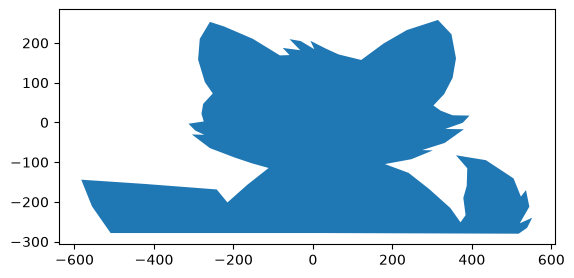

[[1.  0.5]
 [0.  1. ]]


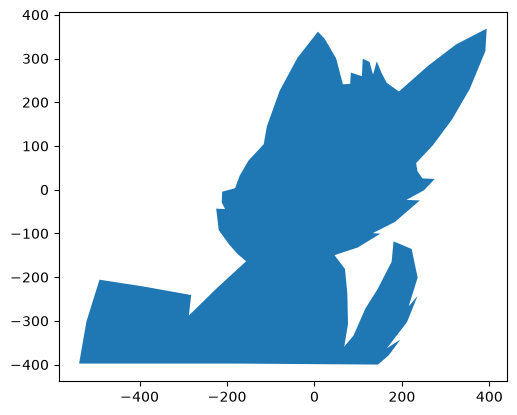

[[0. 1.]
 [1. 0.]]


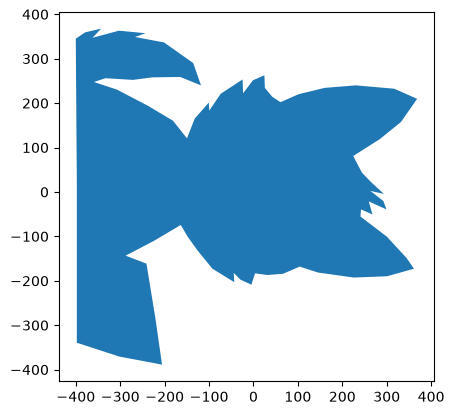

[[ 0.707 -0.707]
 [ 0.707  0.707]]


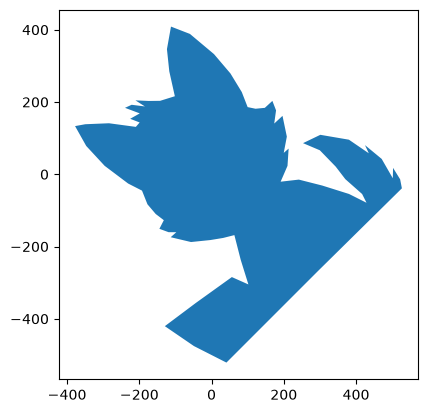

In [6]:
plot_2d(stretch(L, 1.5, 0.7),  stretch_matrix(1.5, 0.7))
plot_2d(shear(L, 0.5, 0),      shear_matrix(0.5, 0))
plot_2d(reflection(L, 1, 1),   reflection_matrix(1, 1))
plot_2d(rotation(L, np.pi/4),  rotation_matrix(np.pi/4))

Changed element a11
[[1.5 0. ]
 [0.  1. ]]


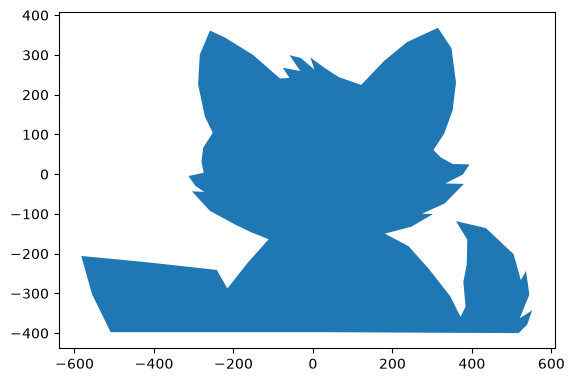

Changed element a12
[[1.  0.5]
 [0.  1. ]]


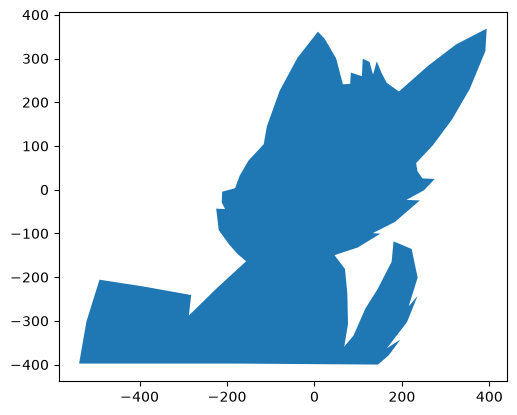

Changed element a21
[[1.  0. ]
 [0.5 1. ]]


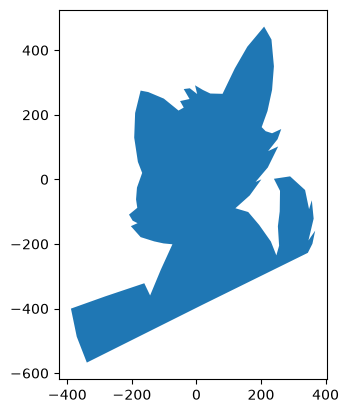

Changed element a22
[[1.  0. ]
 [0.  1.5]]


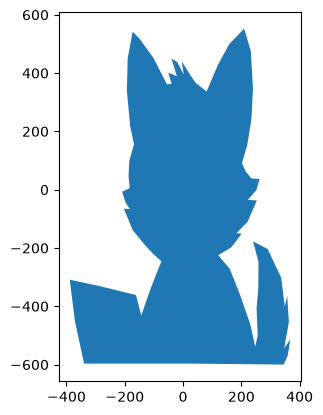

In [7]:
for i in range(2):
    for j in range(2):
        A = np.eye(2)
        A[i, j] += 0.5
        print(f"Changed element a{i+1}{j+1}")
        plot_2d(A @ L, A)

a11 = -1
[[-1  0]
 [ 0  1]]


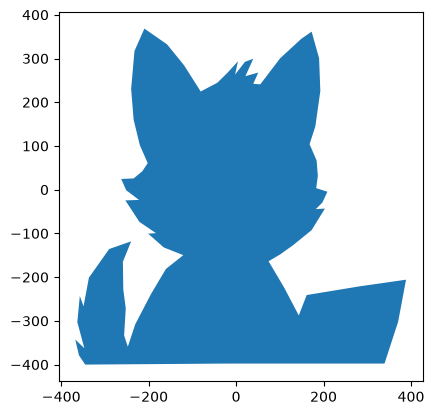

In [8]:
A = np.array([[-1, 0], [0, 1]])
print("a11 = -1")
plot_2d(A @ L, A)

TASK №2

In [9]:
S = stretch_matrix(1.5, 0.7)
H = shear_matrix(0.5, 0)
R = rotation_matrix(np.pi/4)

First matrix: Stretch -> Shear -> Rotation
[[1.5 0. ]
 [0.  0.7]]


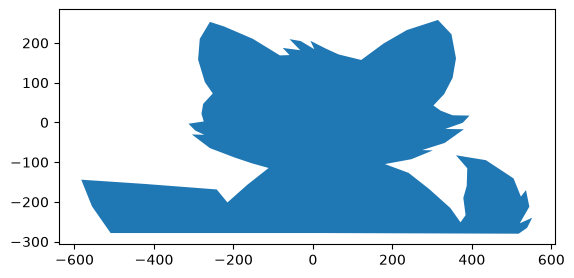

[[1.  0.5]
 [0.  1. ]]


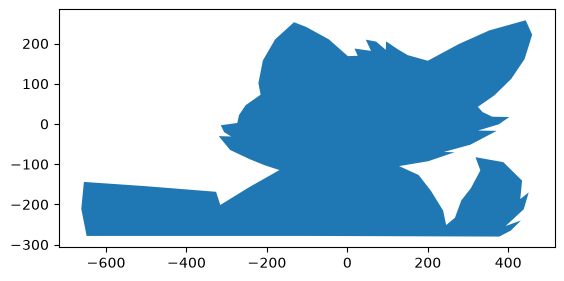

[[ 0.707 -0.707]
 [ 0.707  0.707]]


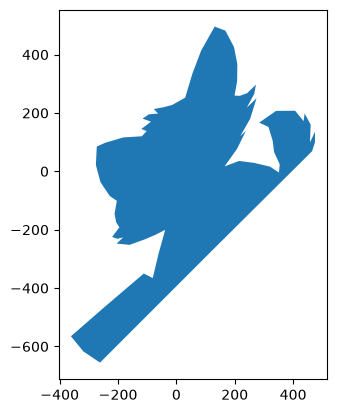

Final matrix:
[[ 1.061 -0.247]
 [ 1.061  0.742]]


In [10]:
print("First matrix: Stretch -> Shear -> Rotation")

X = stretch(L, 1.5, 0.7)
plot_2d(X, S)

X = shear(X, 0.5, 0)
plot_2d(X, H)

X = rotation(X, np.pi/4)
plot_2d(X, R)

M1 = R @ H @ S
print("Final matrix:")
print(M1)

Second matrix: Rotation -> Stretch -> Shear
[[ 0.707 -0.707]
 [ 0.707  0.707]]


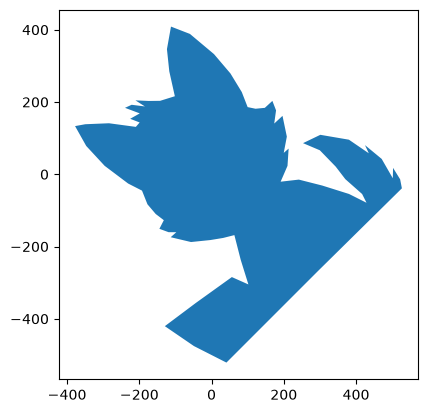

[[1.5 0. ]
 [0.  0.7]]


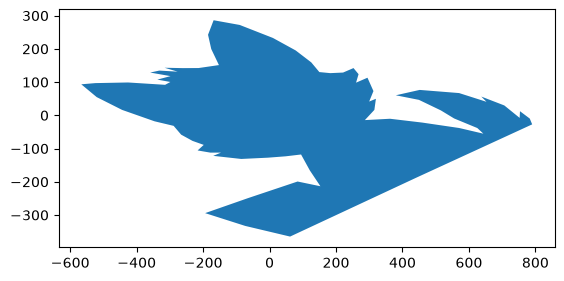

[[1.  0.5]
 [0.  1. ]]


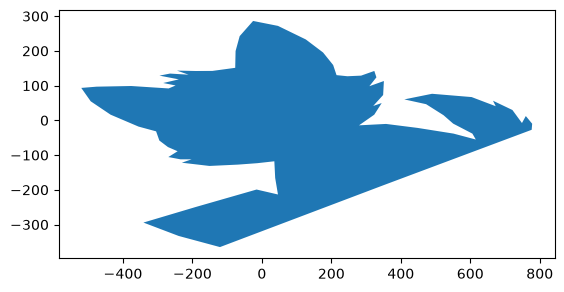

Final matrix:
[[ 1.308 -0.813]
 [ 0.495  0.495]]


In [11]:
print("Second matrix: Rotation -> Stretch -> Shear")

X = rotation(L, np.pi/4)
plot_2d(X, R)

X = stretch(X, 1.5, 0.7)
plot_2d(X, S)

X = shear(X, 0.5, 0)
plot_2d(X, H)

M2 = H @ S @ R
print("Final matrix:")
print(M2)

Third matrix: Shear -> Rotation -> Stretch
[[1.  0.5]
 [0.  1. ]]


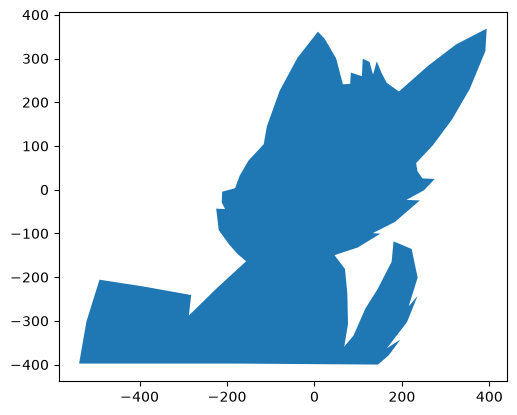

[[ 0.707 -0.707]
 [ 0.707  0.707]]


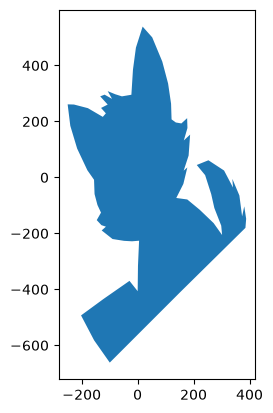

[[1.5 0. ]
 [0.  0.7]]


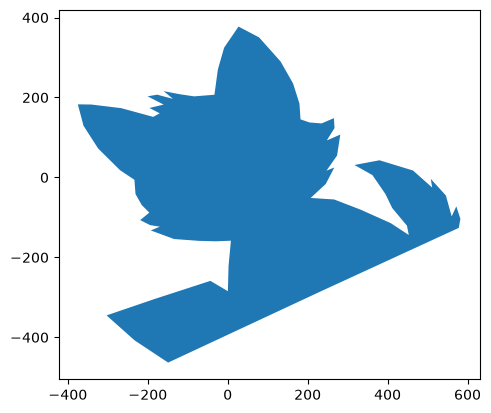

Final matrix:
[[ 1.061 -0.53 ]
 [ 0.495  0.742]]


In [12]:
print("Third matrix: Shear -> Rotation -> Stretch")

X = shear(L, 0.5, 0)
plot_2d(X, H)

X = rotation(X, np.pi/4)
plot_2d(X, R)

X = stretch(X, 1.5, 0.7)
plot_2d(X, S)

M3 = S @ R @ H
print("Final matrix:")
print(M3)

In [13]:
print("M1 == M2:", np.allclose(M1, M2))
print("M1 == M3:", np.allclose(M1, M3))
print("M2 == M3:", np.allclose(M2, M3))

M1 == M2: False
M1 == M3: False
M2 == M3: False


Task №3

In [14]:
def read_off(filename):
    with open(filename, 'r') as f:
        if 'OFF' != f.readline().strip():
            raise ValueError('Not a valid OFF header')
        n_verts, n_faces, _ = map(int, f.readline().strip().split())
        verts = [list(map(float, f.readline().strip().split())) for _ in range(n_verts)]
        faces = [list(map(int, f.readline().strip().split()[1:])) for _ in range(n_faces)]
    return np.array(verts), faces

vertices, faces = read_off("data/airplane_0627.off")   
print(vertices.shape)

(11634, 3)


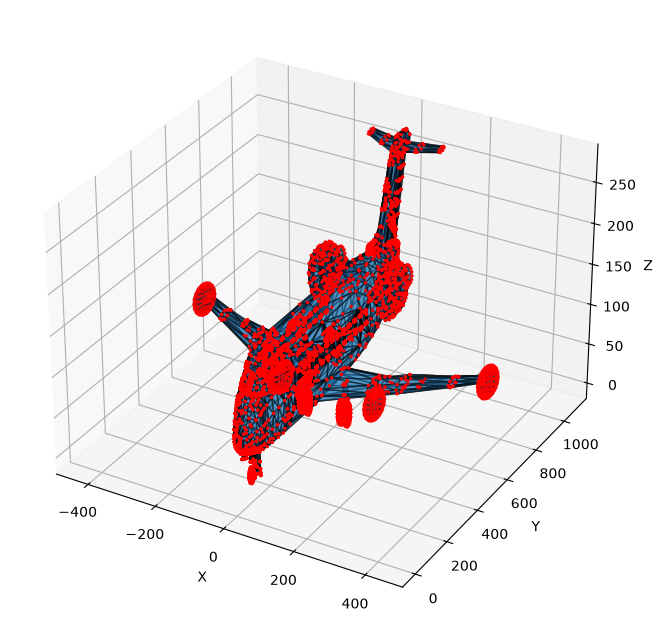

In [15]:
def plot_off(vertices, faces):
    fig = plt.figure(figsize=(8, 8))
    ax = fig.add_subplot(111, projection='3d')
    mesh = Poly3DCollection([vertices[face] for face in faces], alpha=0.3, edgecolor='k')
    ax.add_collection3d(mesh)
    ax.scatter(vertices[:, 0], vertices[:, 1], vertices[:, 2], s=2, c='r')
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")
    ax.auto_scale_xyz(vertices[:, 0], vertices[:, 1], vertices[:, 2])
    plt.show()

plot_off(vertices, faces)

In [16]:
def rot_xy_matrix(theta):
    c, s = np.cos(theta), np.sin(theta)
    return np.array([[c, -s, 0],
                     [s,  c, 0],
                     [0,  0, 1]])

def rot_yz_matrix(theta):
    c, s = np.cos(theta), np.sin(theta)
    return np.array([[1, 0,  0],
                     [0, c, -s],
                     [0, s,  c]])

def rot_xz_matrix(theta):
    c, s = np.cos(theta), np.sin(theta)
    return np.array([[c, 0, -s],
                     [0, 1,  0],
                     [s, 0,  c]])

def rotate_xy(X, theta):
    X = np.array(X, dtype=float, copy=True)
    return (rot_xy_matrix(theta) @ X.T).T

def rotate_yz(X, theta):
    X = np.array(X, dtype=float, copy=True)
    return (rot_yz_matrix(theta) @ X.T).T

def rotate_xz(X, theta):
    X = np.array(X, dtype=float, copy=True)
    return (rot_xz_matrix(theta) @ X.T).T

[[ 0.707 -0.707  0.   ]
 [ 0.707  0.707  0.   ]
 [ 0.     0.     1.   ]]


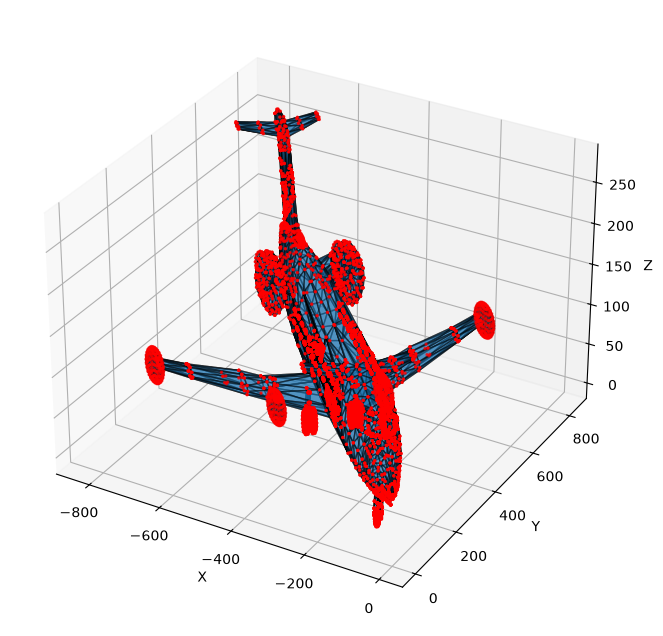

[[ 1.     0.     0.   ]
 [ 0.     0.707 -0.707]
 [ 0.     0.707  0.707]]


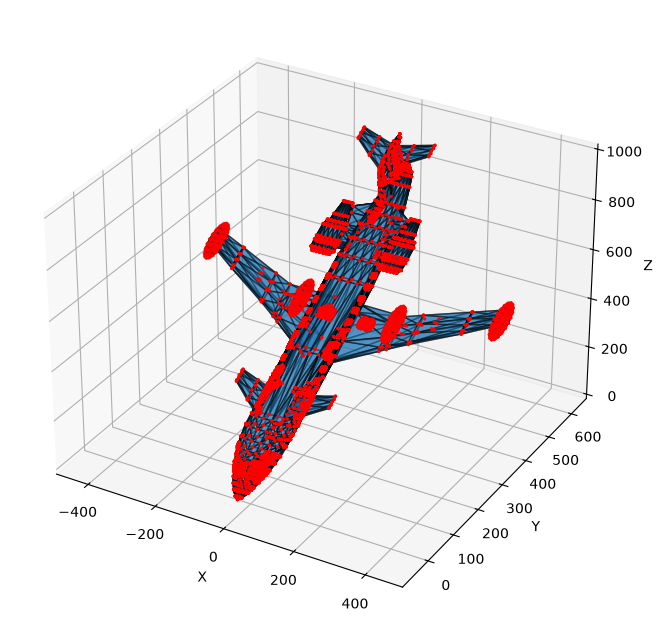

[[ 0.707  0.    -0.707]
 [ 0.     1.     0.   ]
 [ 0.707  0.     0.707]]


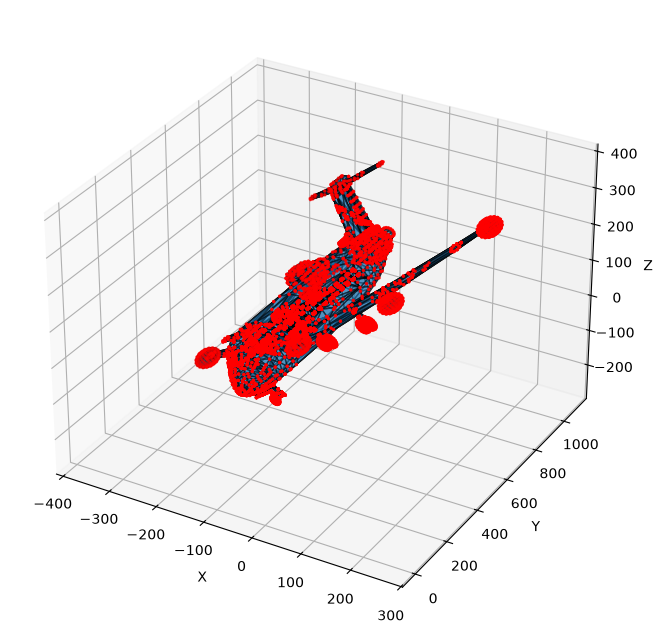

In [17]:
theta = np.pi / 4

V_xy = rotate_xy(vertices, theta)
print(rot_xy_matrix(theta))
plot_off(V_xy, faces)

V_yz = rotate_yz(vertices, theta)
print(rot_yz_matrix(theta))
plot_off(V_yz, faces)

V_xz = rotate_xz(vertices, theta)
print(rot_xz_matrix(theta))
plot_off(V_xz, faces)

Task №4

[[ 0.127 -0.78  -0.612]
 [ 0.354  0.612 -0.707]
 [ 0.927 -0.127  0.354]]


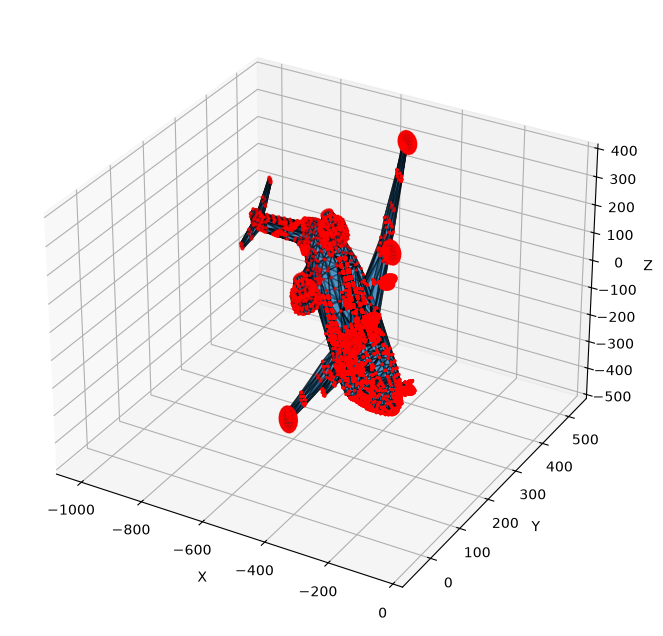

In [18]:
a1, a2, a3 = np.pi/6, np.pi/4, np.pi/3  

V4 = rotate_xy(vertices, a1)
V4 = rotate_yz(V4, a2)
V4 = rotate_xz(V4, a3)

M = rot_xz_matrix(a3) @ rot_yz_matrix(a2) @ rot_xy_matrix(a1)
print(M)
plot_off(V4, faces)